# Task 2: Bennett's S on fake data

**Task:** Create fake labels for two annotators at different prevalences of "offensive", recompute our group's metric and plot it against the prevalence.

Bennett, Alpert & Goldstein's S corrects the percentage agreement $P_o$ for chance by assuming that all $k$ labels are equally likely ($P_e = 1/k$):

$$S = \frac{P_o - 1/k}{1 - 1/k} = 2P_o - 1 \qquad (k = 2)$$

For each prevalence $p$ = 5 %, 10 %, …, 95 % we simulate $N$ = 10,000 texts in two scenarios:

| Scenario | Fake labels | Expected $P_o$ | Expected $S$ |
|---|---|---|---|
| Guessing annotators | both label a share $p$ as offensive, independently of the text | $p^2 + (1-p)^2$ | $(1-2p)^2$ |
| 95 % accurate annotators | both copy the true label (prevalence $p$) and get 5 % of the texts wrong | $0.95^2 + 0.05^2 = 0.905$ | $0.81$ |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
N = 10_000  # large N, so the curves show expected values instead of sampling noise
prevalences = np.linspace(0.05, 0.95, 19).round(2)
scenarios = {"guessing annotators": None, "95 % accurate annotators": 0.95}


def fake_labels(p, accuracy=None):
    """Labels of two annotators for N texts (True = offensive) at prevalence p.
    accuracy=None: both guess; otherwise both copy the true label and err with probability 1 - accuracy."""
    if accuracy is None:
        return rng.random(N) < p, rng.random(N) < p
    truth = rng.random(N) < p
    return truth ^ (rng.random(N) > accuracy), truth ^ (rng.random(N) > accuracy)


def bennett_s(a, b, k=2):
    p_o = np.mean(a == b)
    return (p_o - 1 / k) / (1 - 1 / k)


s = pd.DataFrame({name: [bennett_s(*fake_labels(p, acc)) for p in prevalences] for name, acc in scenarios.items()},
                 index=pd.Index(prevalences, name="prevalence"))
s.loc[[0.05, 0.2, 0.5]].round(2)

,guessing annotators,95 % accurate annotators
prevalence,,
0.05,0.81,0.81
0.20,0.37,0.81
0.50,0.01,0.82


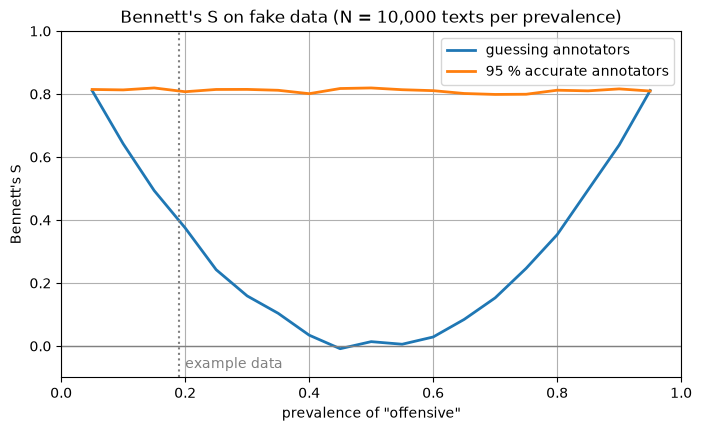

In [2]:
EXAMPLE_PREVALENCE = 0.19  # share of "offensive" labels in the example data (Task 1: 31 of 2 x 81)

ax = s.plot(figsize=(8, 4.5), lw=2, xlim=(0, 1), ylim=(-0.1, 1), grid=True,
            title="Bennett's S on fake data (N = 10,000 texts per prevalence)")
ax.axhline(0, color="gray", lw=1)
ax.axvline(EXAMPLE_PREVALENCE, color="gray", ls=":")
ax.text(EXAMPLE_PREVALENCE + 0.01, -0.07, "example data", color="gray")
ax.set(xlabel='prevalence of "offensive"', ylabel="Bennett's S")
plt.show()

## Results

- **95 % accurate annotators:** S = 0.81 at every prevalence. S only rescales $P_o$ ($S = 2P_o - 1$) and ignores how the labels are distributed.
- **Guessing annotators:** S is 0 only at 50 % prevalence. With skewed labels pure guessing reaches $S = (1-2p)^2$: 0.36 at 20 % and 0.81 at 5 % offensive, as high as the 95 % accurate annotators.
- **Why:** S assumes a chance agreement of $P_e = 0.5$. With skewed labels, two guessing annotators agree on $p^2 + (1-p)^2 > 0.5$ of the texts, and S counts the difference as real agreement.
- **Example data** (≈ 19 % offensive): guessing alone already gives $S = (1 - 2 \cdot 0.19)^2 \approx 0.38$. Our S = 0.83 (Task 1) matches about 95 % accurate annotators, but has to be read against this baseline, not against 0.